# Recommandations à partir des genres

Une première version du modèle utilise seulement les genres de MovieLens. Les favoris servent à construire un profil, puis les autres films sont classés selon leur proximité avec ce profil.

Les identifiants sont les `movieId` de MovieLens. Le modèle utilisé ici est dans `src/models/content_based.py`.

## Catalogue

Les titres et les genres viennent de `data/raw/movies.csv`. Les notes et les tags ne sont pas utilisés pour ce classement.

In [1]:
from pathlib import Path
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/raw/movies.csv").is_file()
    and (p / "src/data/exploration.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt movies-and-me-recommender.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data.exploration import load_movielens

movies = load_movielens(PROJECT_ROOT / "data/raw")["movies"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Films chargés : {len(movies):,} films")
display(movies.head())

Python 3.12.7 | pandas 3.0.6 | scikit-learn 1.9.1
Films chargés : 9,742 films


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## Genres et TF-IDF

Le découpage se fait sur `|`, pour garder `Sci-Fi` et `Film-Noir` comme genres entiers. Les valeurs vides et `(no genres listed)` ne donnent aucun genre. `IMAX` est retiré : c'est un format de projection. Une comparaison avec et sans ce terme est faite plus bas.

TF-IDF donne davantage de poids aux genres rares dans le catalogue. Chaque vecteur de film est ensuite normalisé en L2.

In [2]:
from src.models.content_based import ContentBasedRecommender, tokenize_genres

In [3]:
recommender = ContentBasedRecommender(movies)
features = recommender.feature_matrix
zero_vector_mask = np.asarray(features.getnnz(axis=1) == 0).ravel()
feature_summary = pd.DataFrame({
    "genre": recommender.feature_names,
    "idf": recommender.vectorizer.idf_,
    "num_movies": np.asarray((features > 0).sum(axis=0)).ravel(),
}).sort_values("idf", ascending=False)
print(f"Matrice de genres : {features.shape[0]} films × {features.shape[1]} genres")
print(f"Films avec un vecteur nul : {int(zero_vector_mask.sum())}")
print("Exemple de découpage :", tokenize_genres("Sci-Fi|Film-Noir|IMAX|(no genres listed)"))
display(feature_summary)
display(recommender.movies.loc[zero_vector_mask].head(10))

assert features.shape[0] == len(movies)
assert np.isfinite(features.data).all()
assert "Sci-Fi" in recommender.feature_names and "Film-Noir" in recommender.feature_names
assert "IMAX" not in recommender.feature_names and "(no genres listed)" not in recommender.feature_names

Matrice de genres : 9742 films × 18 genres
Films avec un vecteur nul : 34
Exemple de découpage : ['Film-Noir', 'Sci-Fi']


,genre,idf,num_movies
9,Film-Noir,5.706968,87
17,Western,5.060340,167
11,Musical,4.370174,334
16,War,4.236269,382
6,Documentary,4.095259,440
12,Mystery,3.831675,573
2,Animation,3.767572,611
3,Children,3.684517,664
8,Fantasy,3.525010,779
10,Horror,3.297773,978


,movieId,title,genres
8517,114335,La cravate (1957),(no genres listed)
8684,122888,Ben-hur (2016),(no genres listed)
8687,122896,Pirates of the Caribbean: Dead Men Tell No Tal...,(no genres listed)
8782,129250,Superfast! (2015),(no genres listed)
8836,132084,Let It Be Me (1995),(no genres listed)
8902,134861,Trevor Noah: African American (2013),(no genres listed)
9033,141131,Guardians (2016),(no genres listed)
9053,141866,Green Room (2015),(no genres listed)
9070,142456,The Brand New Testament (2015),(no genres listed)
9091,143410,Hyena Road,(no genres listed)


La matrice contient 18 genres pour 9 742 films. Les 34 films sans genre ont un vecteur nul et ne pourront pas être recommandés avec ce modèle.

`Film-Noir` apparaît dans 87 films et reçoit un poids IDF d'environ 5,71, contre 1,80 pour `Drama`, présent dans 4 361 films. Le poids dépend donc de la fréquence du genre dans le catalogue.

## Trois favoris de science-fiction

Star Wars IV et V ont les mêmes genres. Matrix ajoute `Thriller` à la place d'`Adventure`. La moyenne de leurs vecteurs donne le profil affiché ci-dessous.

Le classement utilise la similarité cosinus entre ce profil et chaque film, en excluant les favoris. Le score va de 0 à 1 et mesure la proximité des genres. Il ne correspond pas à une probabilité d'aimer le film. Le calcul produit un score par film, sans construire de matrice de similarités film × film.

Favoris : Star Wars IV, Star Wars V et Matrix

,movieId,title,genres
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
898,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi
1939,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller


,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
title,,,,,,,,,,,,,,,,,,
Star Wars: Episode IV - A New Hope (1977),0.511908,0.582675,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.63122,0.000000,0.0,0.0
Star Wars: Episode V - The Empire Strikes Back (1980),0.511908,0.582675,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.63122,0.000000,0.0,0.0
"Matrix, The (1999)",0.534972,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.65966,0.527877,0.0,0.0


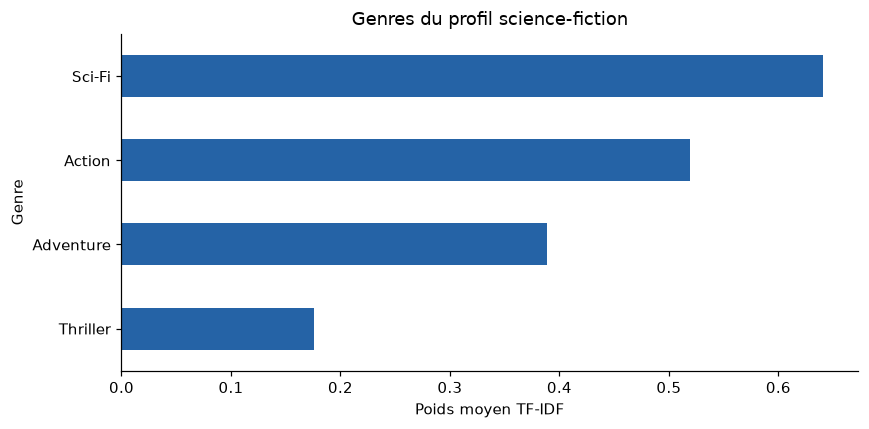

In [4]:
science_fiction_favorites = [260, 1196, 2571]
display(Markdown("Favoris : Star Wars IV, Star Wars V et Matrix"))
favorite_rows = recommender.movies.loc[recommender.movies["movieId"].isin(science_fiction_favorites)]
display(favorite_rows)
positions = favorite_rows.index.to_list()
favorite_vectors = features[positions].toarray()
display(pd.DataFrame(favorite_vectors, index=favorite_rows["title"], columns=recommender.feature_names))
profile_weights = pd.Series(favorite_vectors.mean(axis=0), index=recommender.feature_names)
profile_weights = profile_weights.loc[profile_weights.gt(0)].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
profile_weights.plot.barh(ax=ax, color="#2563a6")
ax.set(title="Genres du profil science-fiction", xlabel="Poids moyen TF-IDF", ylabel="Genre")
fig.tight_layout()
plt.show()

In [5]:
science_fiction_recommendations = recommender.recommend(science_fiction_favorites, n=10)
display(Markdown("Dix recommandations pour ce profil"))
display(science_fiction_recommendations)

Dix recommandations pour ce profil

,movieId,title,genres,score
0,208,Waterworld (1995),Action|Adventure|Sci-Fi,0.965681
1,316,Stargate (1994),Action|Adventure|Sci-Fi,0.965681
2,442,Demolition Man (1993),Action|Adventure|Sci-Fi,0.965681
3,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,0.965681
4,1375,Star Trek III: The Search for Spock (1984),Action|Adventure|Sci-Fi,0.965681
5,1831,Lost in Space (1998),Action|Adventure|Sci-Fi,0.965681
6,2094,"Rocketeer, The (1991)",Action|Adventure|Sci-Fi,0.965681
7,2105,Tron (1982),Action|Adventure|Sci-Fi,0.965681
8,2275,Six-String Samurai (1998),Action|Adventure|Sci-Fi,0.965681
9,2528,Logan's Run (1976),Action|Adventure|Sci-Fi,0.965681


Les dix premiers résultats ont tous `Action|Adventure|Sci-Fi` et le même score, environ 0,966. Waterworld apparaît avant Star Wars VI parce que les ex æquo sont triés par `movieId` croissant : 208 vient avant 1210.

### Un profil animation

Toy Story, Finding Nemo et Incredibles partagent quatre genres. `Fantasy` vient de Toy Story et `Action` d'Incredibles.

In [6]:
animation_favorites = [1, 6377, 8961]
display(Markdown("Favoris : Toy Story, Finding Nemo et Incredibles"))
display(recommender.movies.loc[recommender.movies["movieId"].isin(animation_favorites)])
animation_recommendations = recommender.recommend(animation_favorites, n=10)
display(Markdown("Dix recommandations pour le profil animation"))
display(animation_recommendations)

Favoris : Toy Story, Finding Nemo et Incredibles

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
4360,6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy
5374,8961,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy


Dix recommandations pour le profil animation

,movieId,title,genres,score
0,2141,"American Tail, An (1986)",Adventure|Animation|Children|Comedy,0.976454
1,2355,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,0.976454
2,4990,Jimmy Neutron: Boy Genius (2001),Adventure|Animation|Children|Comedy,0.976454
3,5218,Ice Age (2002),Adventure|Animation|Children|Comedy,0.976454
4,5448,Hey Arnold! The Movie (2002),Adventure|Animation|Children|Comedy,0.976454
5,8974,"SpongeBob SquarePants Movie, The (2004)",Adventure|Animation|Children|Comedy,0.976454
6,27619,"Lion King 1½, The (2004)",Adventure|Animation|Children|Comedy,0.976454
7,33615,Madagascar (2005),Adventure|Animation|Children|Comedy,0.976454
8,38038,Wallace & Gromit in The Curse of the Were-Rabb...,Adventure|Animation|Children|Comedy,0.976454
9,43869,Curious George (2006),Adventure|Animation|Children|Comedy,0.976454


Même constat pour l'animation : les dix résultats ont `Adventure|Animation|Children|Comedy`, avec un score d'environ 0,976. Le tri départage les IDs, pas les histoires ou la qualité des films.

## Le poids d'IMAX

Interstellar est décrit par `Sci-Fi|IMAX` dans ce catalogue. Sans IMAX, son vecteur ne garde qu'un seul genre. La comparaison ci-dessous permet de voir comment ce choix modifie le classement.

In [7]:
with_imax = ContentBasedRecommender(movies, include_imax=True)
comparison = pd.DataFrame([
    {"configuration": "Sans IMAX", "num_features": len(recommender.feature_names),
     "zero_vectors": int(zero_vector_mask.sum())},
    {"configuration": "Avec IMAX", "num_features": len(with_imax.feature_names),
     "zero_vectors": int((with_imax.feature_matrix.getnnz(axis=1) == 0).sum())},
])
display(comparison)
display(movies.loc[movies["movieId"].eq(109487)])
display(Markdown("Interstellar comme favori, sans IMAX"))
display(recommender.recommend([109487], n=5))
display(Markdown("Interstellar comme favori, avec IMAX"))
display(with_imax.recommend([109487], n=5))

,configuration,num_features,zero_vectors
0,Sans IMAX,18,34
1,Avec IMAX,19,34


,movieId,title,genres
8376,109487,Interstellar (2014),Sci-Fi|IMAX


Interstellar comme favori, sans IMAX

,movieId,title,genres,score
0,2311,2010: The Year We Make Contact (1984),Sci-Fi,1.0
1,2526,Meteor (1979),Sci-Fi,1.0
2,2661,It Came from Outer Space (1953),Sci-Fi,1.0
3,2665,Earth vs. the Flying Saucers (1956),Sci-Fi,1.0
4,2698,Zone 39 (1997),Sci-Fi,1.0


Interstellar comme favori, avec IMAX

,movieId,title,genres,score
0,97752,Cloud Atlas (2012),Drama|Sci-Fi|IMAX,0.958772
1,110730,Transcendence (2014),Drama|Sci-Fi|IMAX,0.958772
2,89470,Contagion (2011),Sci-Fi|Thriller|IMAX,0.917532
3,104841,Gravity (2013),Action|Sci-Fi|IMAX,0.915575
4,110553,The Amazing Spider-Man 2 (2014),Action|Sci-Fi|IMAX,0.915575


Sans IMAX, les cinq résultats ont uniquement `Sci-Fi` et un score de 1. Avec IMAX, Cloud Atlas et Transcendence arrivent en tête, autour de 0,959. IMAX ajoute une colonne à la matrice et change nettement les voisins d'Interstellar, sans résoudre les 34 vecteurs nuls.

## Quelques contrôles

Les deux exemples donnent dix films distincts, sans les favoris. Les assertions vérifient aussi les scores et la stabilité de l'ordre quand les favoris sont réordonnés ou répétés.

Une liste vide, un ID inconnu ou des favoris sans genre exploitable provoquent une `ValueError`. Un favori sans genre peut être conservé avec d'autres favoris : il n'ajoute simplement aucun signal au profil.

Seuls les candidats ayant un score positif sont retournés. S'il y en a moins que le nombre demandé, la liste est plus courte ; sans candidat, elle est vide.

In [8]:
for favorites, recommendations in [
    (science_fiction_favorites, science_fiction_recommendations),
    (animation_favorites, animation_recommendations),
]:
    assert len(recommendations) == 10
    assert recommendations["movieId"].is_unique
    assert not recommendations["movieId"].isin(favorites).any()
    assert recommendations["score"].between(0, 1).all()
    assert recommendations["score"].gt(0).all()
    assert recommendations["score"].is_monotonic_decreasing
    pd.testing.assert_frame_equal(recommendations, recommender.recommend(favorites[::-1], n=10))
    pd.testing.assert_frame_equal(recommendations, recommender.recommend(favorites + [favorites[0]], n=10))
print("Les deux listes contiennent 10 films distincts, sans les favoris.")

no_genre_id = int(recommender.movies.loc[zero_vector_mask, "movieId"].iloc[0])
for label, favorites in [("Liste de favoris vide", []), ("ID absent du catalogue", [987654321]), ("Favori sans genre", [no_genre_id])]:
    try:
        recommender.recommend(favorites)
    except ValueError as error:
        print(f"{label} → {error}")
    else:
        raise AssertionError(f"Une ValueError était attendue pour : {label}")

Les deux listes contiennent 10 films distincts, sans les favoris.
Liste de favoris vide → At least one favorite movieId is required.
ID absent du catalogue → Unknown MovieLens movieId values: [987654321]
Favori sans genre → Favorites have no usable genres; cannot build a profile.


## Bilan

Les deux profils donnent chacun dix résultats, mais les ex æquo montrent la limite d'une représentation par genres. Le modèle rapproche des catégories de films ; il ne distingue pas leur intrigue ou leur qualité, et ne tient compte d'aucune note.

Le catalogue est celui de MovieLens utilisé ici, avec des films et des interactions arrêtés en 2018. La qualité des recommandations reste à mesurer sur des interactions mises de côté. Les scores et les contrôles de ce notebook ne suffisent pas à l'établir.

In [9]:
summary = {
    "num_movies": len(recommender.movies),
    "num_features": len(recommender.feature_names),
    "num_zero_vectors": int(zero_vector_mask.sum()),
    "num_example_profiles_validated": 2,
    "num_recommendations_per_example": len(science_fiction_recommendations),
    "favorites_excluded": not science_fiction_recommendations["movieId"].isin(science_fiction_favorites).any(),
    "unique_recommendations": science_fiction_recommendations["movieId"].is_unique,
}
print(json.dumps(summary, indent=4, default=bool))

{
    "num_movies": 9742,
    "num_features": 18,
    "num_zero_vectors": 34,
    "num_example_profiles_validated": 2,
    "num_recommendations_per_example": 10,
    "favorites_excluded": true,
    "unique_recommendations": true
}
